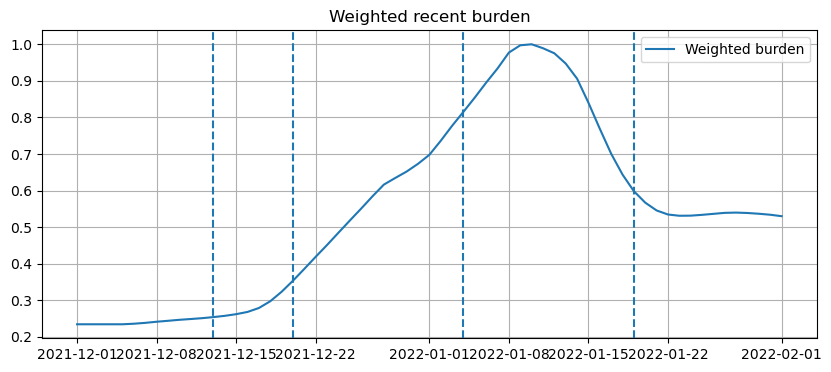

In [1]:
# =========================================================
# BLOCK 1: data + weighted recent burden
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"]
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# parameters
tau = 4
gamma = 1/7
N = 67_000_000

# breakpoints
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(dates == pd.Timestamp(d))[0][0]) for d in break_dates]

def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i+1]) for i in range(len(bounds)-1)]

segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

# delay
def apply_delay(x, tau):
    y = np.empty_like(x)
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

obs_delayed = apply_delay(obs_cases, tau)

# =========================================================
# weighted burden (exponential)
# =========================================================
L = 7
lam = 0.75

weights = np.array([lam**ell for ell in range(L)], dtype=float)
weights = weights / weights.sum()

burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_delayed[idx])
            wts.append(weights[ell])

    vals = np.array(vals)
    wts = np.array(wts)
    wts = wts / wts.sum()

    burden[t] = np.sum(wts * vals)

# normalize
burden = burden / np.max(burden)

# plot burden
plt.figure(figsize=(10,4))
plt.plot(dates, burden, label="Weighted burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")
plt.legend()
plt.title("Weighted recent burden")
plt.grid()
plt.show()

In [2]:
# =========================================================
# BLOCK 2: model + fitting
# =========================================================
from scipy.optimize import minimize

def get_segment_index(t, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t < b:
            return j
    return len(segment_bounds) - 1

# mm burden beta
def beta_t(t, params):
    j = get_segment_index(t, segment_bounds)
    p = params[j]
    B = burden[t]
    return p["beta0"] / (1 + p["k"] * (B / (p["h"] + B + 1e-12)))

def unpack(theta):
    params = []
    pos = 0
    for _ in range(n_seg):
        params.append({
            "beta0": theta[pos],
            "k": theta[pos+1],
            "h": theta[pos+2]
        })
        pos += 3

    rho = theta[pos]
    I0 = theta[pos+1]

    return params, rho, I0

# simulation
def simulate(theta):
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0

    for t in range(T):
        b = beta_t(t, params)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T-1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t+1] = S[t] - new_inf
            I[t+1] = I[t] + new_inf - new_rec
            R[t+1] = R[t] + new_rec

    fitted = rho * apply_delay(incidence, tau)

    return beta_path, incidence, fitted

# loss
def loss(theta):
    try:
        _, _, fitted = simulate(theta)
        return np.mean((np.log(fitted+1) - np.log(obs_cases+1))**2)
    except:
        return 1e10

# init
x0 = []
bounds = []

for _ in range(n_seg):
    x0 += [0.2, 2.0, 0.3]
    bounds += [(1e-6,1), (0,20), (0.01,2)]

x0 += [1.0, obs_cases[0]*5]
bounds += [(1e-6,10), (1,5e6)]

x0 = np.array(x0)

# optimize
res = minimize(loss, x0, bounds=bounds, method="L-BFGS-B")

theta_hat = res.x
beta_path, incidence, fitted_cases = simulate(theta_hat)

print("done")

done


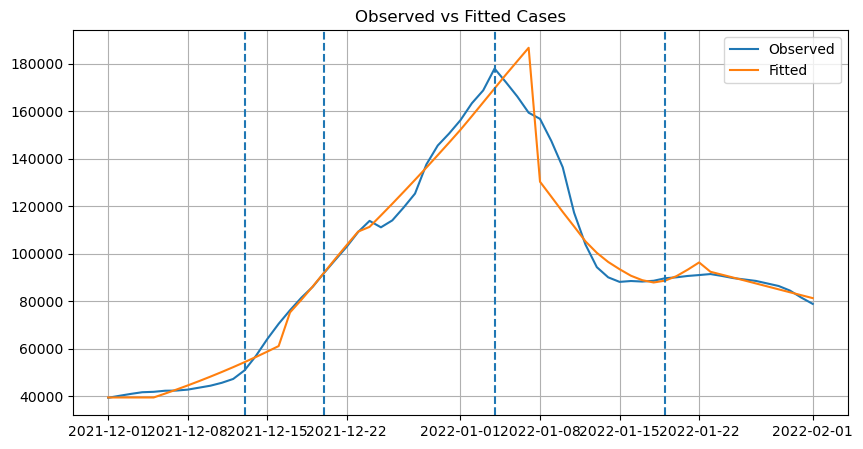

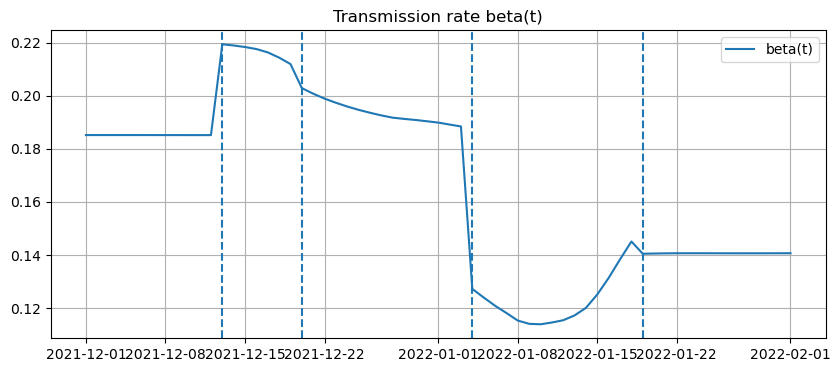

   segment  beta_start  beta_end  beta_mean
0        1    0.185170  0.185154   0.185165
1        2    0.219358  0.211908   0.216671
2        3    0.202851  0.188416   0.193877
3        4    0.127231  0.145098   0.122741
4        5    0.140490  0.140682   0.140645


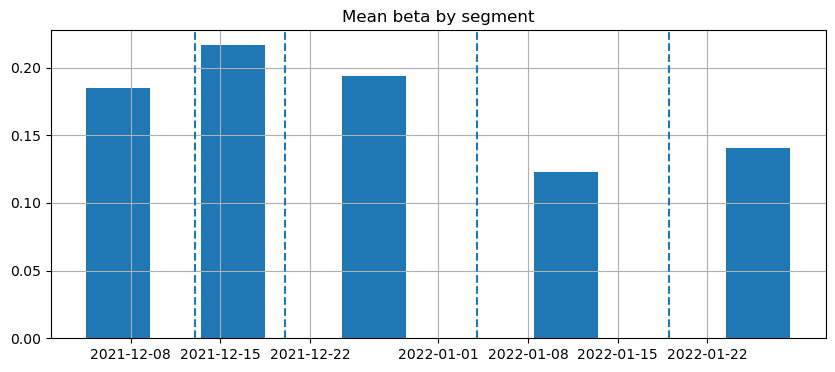

In [3]:
# =========================================================
# BLOCK 3: results + plots + summary
# =========================================================

# --- plot cases ---
plt.figure(figsize=(10,5))
plt.plot(dates, obs_cases, label="Observed")
plt.plot(dates, fitted_cases, label="Fitted")

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.legend()
plt.title("Observed vs Fitted Cases")
plt.grid()
plt.show()

# --- plot beta ---
plt.figure(figsize=(10,4))
plt.plot(dates, beta_path, label="beta(t)")

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.legend()
plt.title("Transmission rate beta(t)")
plt.grid()
plt.show()

# --- segment summary ---
summary = []

for j, (a,b) in enumerate(segment_bounds):
    seg_beta = beta_path[a:b]

    summary.append({
        "segment": j+1,
        "beta_start": seg_beta[0],
        "beta_end": seg_beta[-1],
        "beta_mean": np.mean(seg_beta)
    })

seg_df = pd.DataFrame(summary)
print(seg_df)

# --- mean beta plot ---
mid_dates = [dates.iloc[(a+b)//2] for (a,b) in segment_bounds]

plt.figure(figsize=(10,4))
plt.bar(mid_dates, seg_df["beta_mean"], width=5)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Mean beta by segment")
plt.grid()
plt.show()